In [ ]:
!pip install -q torch torchvision matplotlib pillow

In [ ]:
import os, tarfile, urllib.request, random
from glob import glob
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/AI"     # change to your folder
os.makedirs(BASE, exist_ok=True)
CKPT = f"{BASE}/pix2pix_ckpt.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
DATASET, IMG, BATCH, EPOCHS, LAMBDA_L1 = "facades", 256, 4, 40, 100
print("device:", device)   # should say cuda

Mounted at /content/drive
device: cuda


In [ ]:
url = f"http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/{DATASET}.tar.gz"
if not os.path.exists(DATASET):
    urllib.request.urlretrieve(url, f"{DATASET}.tar.gz")
    with tarfile.open(f"{DATASET}.tar.gz") as t:
        t.extractall(".")
print(os.listdir(DATASET))

['val', 'test', 'train']


In [ ]:
class PairedDataset(Dataset):
    def __init__(self, folder, train=True):
        self.files = sorted(glob(f"{folder}/*.jpg"))
        self.train = train
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")
        w, h = img.size
        a = img.crop((0, 0, w // 2, h))   # input
        b = img.crop((w // 2, 0, w, h))   # target
        if self.train:
            a, b = a.resize((286, 286), Image.BICUBIC), b.resize((286, 286), Image.BICUBIC)
            x, y = random.randint(0, 30), random.randint(0, 30)
            a, b = a.crop((x, y, x+IMG, y+IMG)), b.crop((x, y, x+IMG, y+IMG))
            if random.random() < 0.5:
                a, b = a.transpose(Image.FLIP_LEFT_RIGHT), b.transpose(Image.FLIP_LEFT_RIGHT)
        else:
            a, b = a.resize((IMG, IMG), Image.BICUBIC), b.resize((IMG, IMG), Image.BICUBIC)
        tf = T.Compose([T.ToTensor(), T.Normalize([0.5]*3, [0.5]*3)])
        return tf(a), tf(b)

train_dl = DataLoader(PairedDataset(f"{DATASET}/train"), BATCH, shuffle=True, num_workers=2)
val_dl = DataLoader(PairedDataset(f"{DATASET}/val", train=False), 4)
x, y = next(iter(train_dl)); print(x.shape, y.shape)

torch.Size([4, 3, 256, 256]) torch.Size([4, 3, 256, 256])


In [ ]:
def down(i, o, norm=True):
    layers = [nn.Conv2d(i, o, 4, 2, 1, bias=False)]
    if norm: layers.append(nn.BatchNorm2d(o))
    layers.append(nn.LeakyReLU(0.2))
    return nn.Sequential(*layers)

def up(i, o, dropout=False):
    layers = [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o)]
    if dropout: layers.append(nn.Dropout(0.5))
    layers.append(nn.ReLU())
    return nn.Sequential(*layers)

In [ ]:
class UNetGenerator(nn.Module):
    def __init__(self, c_in=3, c_out=3):
        super().__init__()
        self.downs = nn.ModuleList([
            down(c_in, 64, norm=False), down(64, 128), down(128, 256), down(256, 512),
            down(512, 512), down(512, 512), down(512, 512), down(512, 512, norm=False)])
        self.ups = nn.ModuleList([
            up(512, 512, True), up(1024, 512, True), up(1024, 512, True), up(1024, 512),
            up(1024, 256), up(512, 128), up(256, 64)])
        self.final = nn.Sequential(nn.ConvTranspose2d(128, c_out, 4, 2, 1), nn.Tanh())
    def forward(self, x):
        skips = []
        for d in self.downs:
            x = d(x); skips.append(x)
        skips = skips[:-1][::-1]
        for u, s in zip(self.ups, skips):
            x = torch.cat([u(x), s], 1)
        return self.final(x)

In [ ]:
class PatchDiscriminator(nn.Module):
    def __init__(self, c_in=6):
        super().__init__()
        self.net = nn.Sequential(
            down(c_in, 64, norm=False), down(64, 128), down(128, 256),
            nn.ZeroPad2d(1), nn.Conv2d(256, 512, 4, 1, bias=False),
            nn.BatchNorm2d(512), nn.LeakyReLU(0.2),
            nn.ZeroPad2d(1), nn.Conv2d(512, 1, 4, 1))
    def forward(self, x, y):
        return self.net(torch.cat([x, y], 1))

In [ ]:
def init_w(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0, 0.02)

G, D = UNetGenerator().to(device), PatchDiscriminator().to(device)
G.apply(init_w); D.apply(init_w)
opt_G = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
bce, l1 = nn.BCEWithLogitsLoss(), nn.L1Loss()

start = 0
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"])
    opt_G.load_state_dict(ck["opt_G"]); opt_D.load_state_dict(ck["opt_D"])
    start = ck["epoch"]; print("Resumed from epoch", start)

print(G(x.to(device)).shape, D(x.to(device), y.to(device)).shape)  # [4,3,256,256] and [4,1,30,30]

Resumed from epoch 40
torch.Size([4, 3, 256, 256]) torch.Size([4, 1, 30, 30])


In [ ]:
def show(n=3):
    G.eval()
    xv, yv = next(iter(val_dl))
    with torch.no_grad(): fake = G(xv.to(device)).cpu()
    G.train()
    fig, ax = plt.subplots(n, 3, figsize=(9, 3*n))
    for i in range(n):
        for j, (im, t) in enumerate(zip([xv[i], fake[i], yv[i]], ["Input", "Generated", "Target"])):
            ax[i, j].imshow((im.permute(1, 2, 0)*0.5+0.5).clamp(0, 1))
            ax[i, j].set_title(t); ax[i, j].axis("off")
    plt.show()

In [ ]:
for epoch in range(start, EPOCHS):
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        fake = G(x)

        opt_D.zero_grad()
        pr, pf = D(x, y), D(x, fake.detach())
        loss_D = 0.5 * (bce(pr, torch.ones_like(pr)) + bce(pf, torch.zeros_like(pf)))
        loss_D.backward(); opt_D.step()

        opt_G.zero_grad()
        pf = D(x, fake)
        loss_G = bce(pf, torch.ones_like(pf)) + LAMBDA_L1 * l1(fake, y)
        loss_G.backward(); opt_G.step()

    print(f"epoch {epoch+1}/{EPOCHS}  D={loss_D.item():.3f}  G={loss_G.item():.3f}")
    torch.save({"G": G.state_dict(), "D": D.state_dict(), "opt_G": opt_G.state_dict(),
                "opt_D": opt_D.state_dict(), "epoch": epoch+1}, CKPT)
    if (epoch + 1) % 10 == 0: show()

print("Training done. Saved to:", CKPT)

Training done. Saved to: /content/drive/MyDrive/AI/pix2pix_ckpt.pth


In [ ]:
torch.save(G.state_dict(), f"{BASE}/pix2pix_generator.pth")
print("Saved to:", f"{BASE}/pix2pix_generator.pth")

Saved to: /content/drive/MyDrive/AI/pix2pix_generator.pth


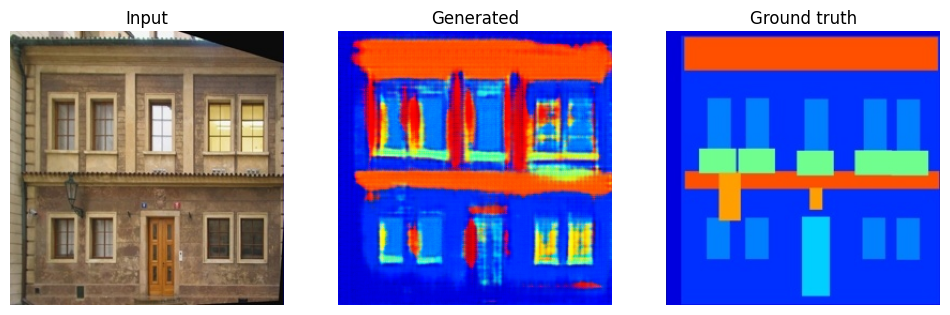

In [ ]:
def translate(path, use_left_half=True):
    img = Image.open(path).convert("RGB")
    if use_left_half:
        w, h = img.size
        img = img.crop((0, 0, w // 2, h))
    img = img.resize((IMG, IMG), Image.BICUBIC)
    tf = T.Compose([T.ToTensor(), T.Normalize([0.5]*3, [0.5]*3)])
    G.eval()
    with torch.no_grad():
        out = G(tf(img).unsqueeze(0).to(device))[0].cpu()
    return img, T.ToPILImage()((out * 0.5 + 0.5).clamp(0, 1))

inp, gen = translate("facades/val/1.jpg")
real = Image.open("facades/val/1.jpg").convert("RGB")
real = real.crop((real.size[0] // 2, 0, real.size[0], real.size[1])).resize((IMG, IMG))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax, [inp, gen, real], ["Input", "Generated", "Ground truth"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.show()

In [ ]:
gen.save(f"{BASE}/generated_1.png")

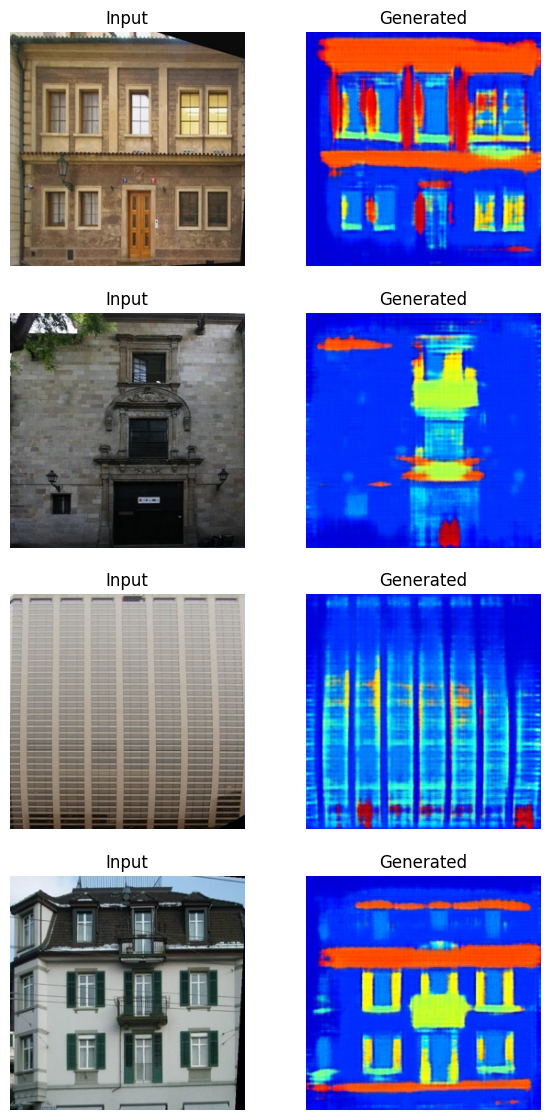

In [ ]:
fig, ax = plt.subplots(4, 2, figsize=(7, 14))
for r, n in enumerate([1, 5, 10, 20]):
    i, g = translate(f"facades/val/{n}.jpg")
    ax[r, 0].imshow(i); ax[r, 0].set_title("Input"); ax[r, 0].axis("off")
    ax[r, 1].imshow(g); ax[r, 1].set_title("Generated"); ax[r, 1].axis("off")
plt.show()

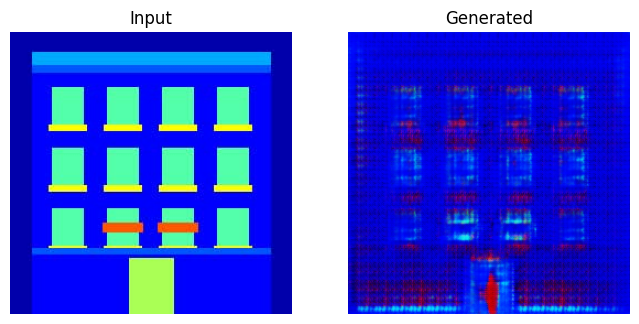

In [ ]:
inp, gen = translate("my_image.png", use_left_half=False)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(inp); ax[0].set_title("Input"); ax[0].axis("off")
ax[1].imshow(gen); ax[1].set_title("Generated"); ax[1].axis("off")
plt.show()